# Results - Pliny's Wall of Fame


This code produces graphs and calculations that are presented and discussed in the paper "Pliny’s “Wall of Fame”: A Digital Semantic Approach to Citations and Sources in Books 2-6 of the Naturalis Historia", published in DH Benelux Journal.

The notebook is divided in the following sections:
- <u>Most cited authors</u>: counts the most cited authors in the total corpus and in the group;
- <u>Citizenship</u>: analyzes the citizenship values across the corpus, for all the individuals and for the authors only;
- <u>Language</u>: counts the number of mentions of authors per language group and tests the significance of the results;
- <u>Occupation</u>: analyzes the occupation values across the corpus for the mentioned authors, counts the number of mentions per political status and tests the significance of the result;
- <u>Chronology</u>: analyzes the chronological values across the corpus for the mentioned authors, counts the number of mentions per Augustan source and tests the significance of the result.

The notebook can be run starting from two files:
- '**nh_categorized.csv**', produced with the notebook wikidata_categorization.ipynb
- '**nh_annotated.csv**', published in the repository.

## Import

In [133]:
import pandas as pd
import matplotlib.pyplot as plt
import textwrap
from scipy.stats import mannwhitneyu
import numpy as np

## Upload dataset

In [149]:
nh = pd.read_csv('nh_annotated.csv')
# nh = pd.read_csv('nh_categorized.csv')


C:\Users\u0172188\AppData\Local\Temp\ipykernel_72268\2473503807.py:1: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  nh = pd.read_csv('nh_annotated.csv')


In [151]:
#creating window for the occupation distribution
window_size = 5000
nh['window'] = nh.index // window_size

#defining groups
nh_persons = nh[nh['gold_ner'] == 'B-PERS'] #we keep only the Beginning token to count the exact number of mentions
nh_humans = nh_persons[nh_persons['is_human'] == True]
nh_authors = nh_humans[nh_humans['is_author_index'] == True]

## Most cited authors

In [153]:
most_cited_authors = nh_authors.groupby(['wikidata_qid', 'Wikidata_label', 'language_group']).size().sort_values(ascending=False)
print(most_cited_authors)
#most_cited_authors.to_csv("most_cited_authors.csv")

wikidata_qid  Wikidata_label            language_group
Q48174        Marcus Vipsanius Agrippa  Latin             34
Q315670       Juba II                   Greek             20
Q1351420      Isidoros of Charax        Greek             17
Q43182        Eratosthenes              Greek             17
Q472620       Artemidorus of Ephesus    Greek             16
                                                          ..
Q3614494      Amometus                  Greek              1
Q36303        Thales                    Greek              1
Q3635627      Basilis                   Greek              1
Q41683        Thucydides                Greek              1
Q961762       Patrocles                 Greek              1
Length: 108, dtype: int64


Save results for each book in a separate csv

In [155]:
book_range = range(2,7)

for b in book_range:
    book_text = nh_authors[nh_authors['book'] == b]
    book_counts = book_text.groupby(['wikidata_qid', 'Wikidata_label', 'language_group']).size().sort_values(ascending=False)
    book_counts.to_csv(f'most_cited_authors_book{b}.csv')


## Citizenship

This code creates a graph showing the citizenship distribution of all the humans in the corpus

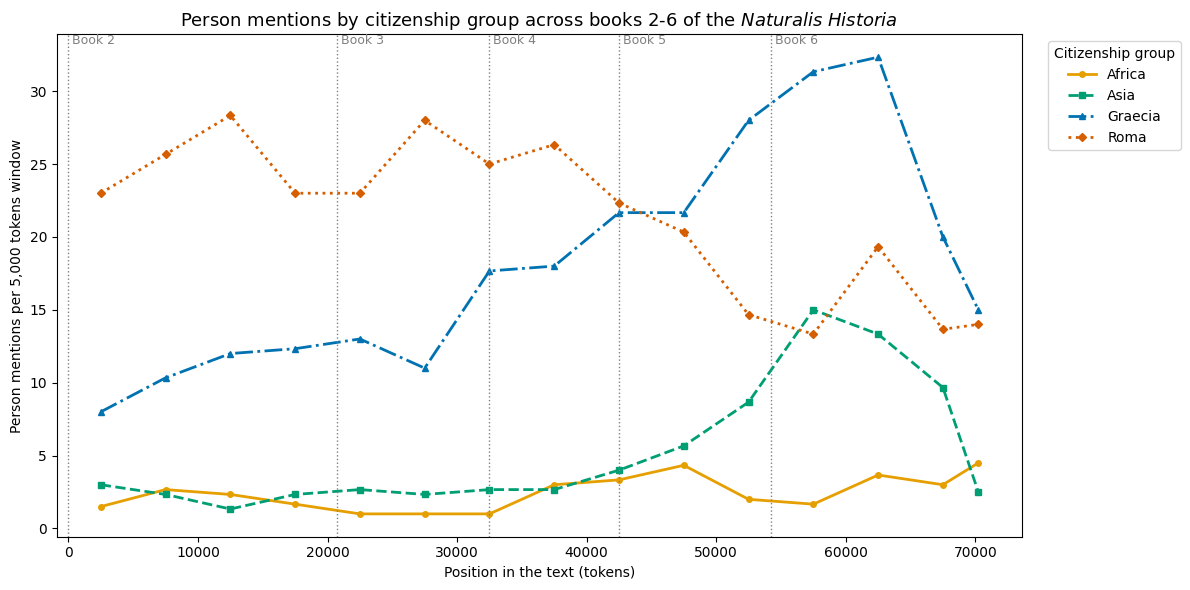

In [157]:
# Denominator: all tokens in each window (PERS or not)
tokens_per_window = nh.groupby('window').size()

# Person mentions per citizenship group and window
counts = pd.crosstab(nh_humans['window'], nh_humans['citizenship_group'])
counts = counts.reindex(tokens_per_window.index, fill_value=0)
#we drop Germania because it's just one mention of one individual
counts = counts.drop(columns=['Germania'])

# Rate per 1,000 tokens (the last window may be shorter > normalize)
rates = counts.div(tokens_per_window, axis=0) * 1000

# Smooth to make trends easier to see
smooth = counts.rolling(window=3, center=True, min_periods=1).mean()

# X axis: token position at the center of each window
x = tokens_per_window.index * window_size + tokens_per_window / 2


#define a fixed color map and style map
color_map = {
    'Graecia':  '#0072B2',
    'Roma': '#D55E00',
    'Asia': '#009E73',
    'Africa': '#E69F00'
}
styles = ['-', '--', '-.', ':']
markers = ['o', 's', '^', 'D']

#plot
fig, ax = plt.subplots(figsize=(12, 6))
for i, group in enumerate(smooth.columns):
    ax.plot(
        x, smooth[group],
        color=color_map.get(group),
        linestyle=styles[i % len(styles)],
        marker=markers[i % len(markers)], markersize=4,
        linewidth=2, label=group
    )

# Mark where each book begins
book_starts = nh.reset_index().groupby('book', sort=False)['index'].min()
for book, start in book_starts.items():
    ax.axvline(start, color='gray', linestyle=':', linewidth=1)
    ax.text(start, ax.get_ylim()[1], f' Book {book}', va='top', fontsize=9, color='gray')

ax.set_xlabel('Position in the text (tokens)')
ax.set_ylabel('Person mentions per 5,000 tokens window')
ax.set_title(r'Person mentions by citizenship group across books 2-6 of the $\mathit{Naturalis\ Historia}$ ', fontsize=13)
ax.legend(title='Citizenship group', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

#----to save-----
# plt.savefig('citizenship_across_books.pdf')

This code instead creates a graph showing the citizenship distribution only of the authors.

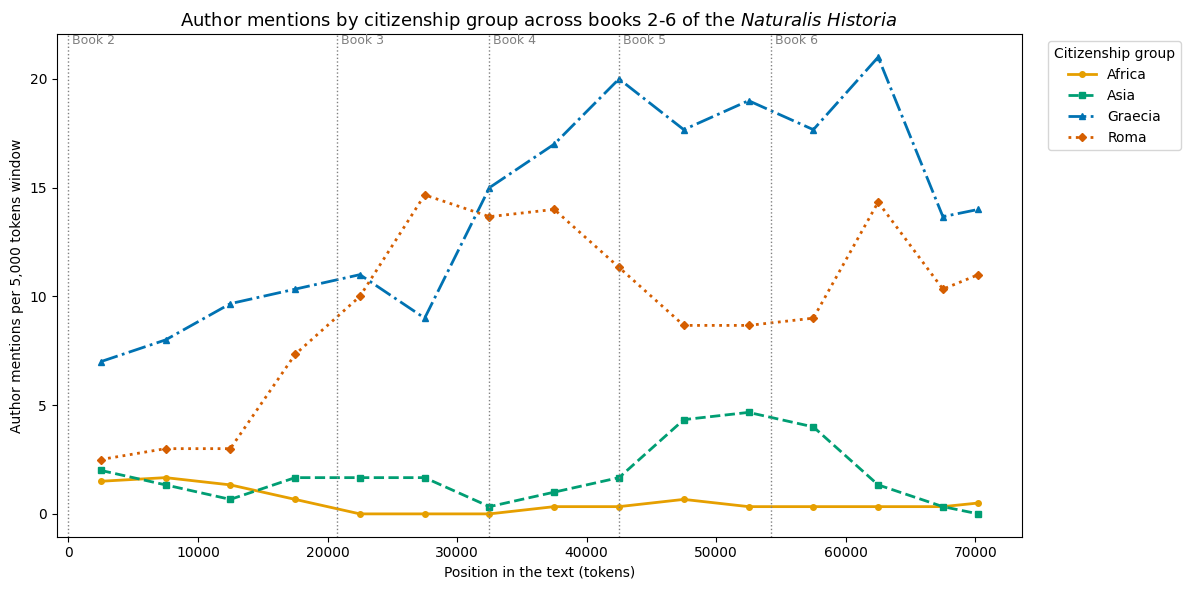

In [159]:
# Denominator: all tokens in each window (PERS or not)
tokens_per_window = nh.groupby('window').size()

# Person mentions per citizenship group and window
counts = pd.crosstab(nh_authors['window'], nh_authors['citizenship_group'])
counts = counts.reindex(tokens_per_window.index, fill_value=0)


# Rate per 1,000 tokens (the last window may be shorter > normalize)
rates = counts.div(tokens_per_window, axis=0) * 1000

# Smooth to make trends easier to see
smooth = counts.rolling(window=3, center=True, min_periods=1).mean()

# X axis: token position at the center of each window
x = tokens_per_window.index * window_size + tokens_per_window / 2

# Fixed colors, line styles and markers per group (reuse your mapping)
#define a fixed color map
color_map = {
    'Graecia':  '#0072B2',
    'Roma': '#D55E00',
    'Asia': '#009E73',
    'Africa': '#E69F00'
}
styles = ['-', '--', '-.', ':']
markers = ['o', 's', '^', 'D']

#plot
fig, ax = plt.subplots(figsize=(12, 6))
for i, group in enumerate(smooth.columns):
    ax.plot(
        x, smooth[group],
        color=color_map.get(group),
        linestyle=styles[i % len(styles)],
        marker=markers[i % len(markers)], markersize=4,
        linewidth=2, label=group
    )

# Mark where each book begins
book_starts = nh.reset_index().groupby('book', sort=False)['index'].min()
for book, start in book_starts.items():
    ax.axvline(start, color='gray', linestyle=':', linewidth=1)
    ax.text(start, ax.get_ylim()[1], f' Book {book}', va='top', fontsize=9, color='gray')

ax.set_xlabel('Position in the text (tokens)')
ax.set_ylabel('Author mentions per 5,000 tokens window')
ax.set_title(r'Author mentions by citizenship group across books 2-6 of the $\mathit{Naturalis\ Historia}$ ', fontsize=13)
ax.legend(title='Citizenship group', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

#----to save-----
# plt.savefig('citizenship_across_books_authors.pdf')

## Language

We focus on the language of the mentioned authors

In [161]:
#defining unique_authors per each book
unique_authors = nh_authors.drop_duplicates(subset=['book','wikidata'])

In [163]:
def lang_stat(nh_authors, unique_authors, book):
    """ Language statistics: mean, median, total mentions,
    unique authors per book """
    authors_mentions_book = nh_authors[nh_authors['book'] == book]
    unique_authors_book = unique_authors[unique_authors['book'] == book]
    per_author = authors_mentions_book.groupby([ 'language_group', 'wikidata']).size()
    median = per_author.groupby('language_group').median()
    mean = per_author.groupby('language_group').mean()

    comparison = pd.DataFrame({
        'mean': mean,
        'median': median
    })
    
    lang_counts = pd.Series(authors_mentions_book['language_group'].value_counts())
    lang_counts_u = pd.Series(unique_authors_book['language_group'].value_counts())
    
    lang_df_count = pd.DataFrame({'total':lang_counts, 'unique':lang_counts_u})
    total_comparison = pd.concat([comparison, lang_df_count], axis = 1)

    
    return total_comparison

book_range = range(2, 7)
results = []
for b in book_range:
    book_comparison = lang_stat(nh_authors, unique_authors, book=b)
    results.append(book_comparison)

final = pd.concat(results, keys=book_range, names=['book', 'language_group'])
 
print(final)

                         mean  median  total  unique
book language_group                                 
2    Greek           1.806452     1.0     56      31
     Latin           1.333333     1.0     12       9
     Other           1.000000     1.0      3       3
3    Greek           1.307692     1.0     17      13
     Latin           3.000000     1.5     42      14
4    Greek           1.880000     1.0     47      25
     Latin           5.250000     4.0     21       4
5    Greek           2.409091     1.0     53      22
     Latin           2.000000     1.0     12       6
     Other           1.000000     1.0      1       1
6    Greek           2.896552     2.0     84      29
     Latin           2.727273     2.0     30      11
     Other           1.000000     1.0      1       1


#### Statistical test

In [165]:
nh3 = nh_authors[nh_authors['book'] == 3]
author_stats_nh3 = nh3.groupby(['Wikidata_label',  'language_group']).size().reset_index(name='n_mentions')


In [167]:

latin_nh3 = author_stats_nh3[author_stats_nh3['language_group']=='Latin']['n_mentions']
externis_nh3 = author_stats_nh3[author_stats_nh3['language_group'] == 'Greek']['n_mentions']

stat, p = mannwhitneyu(latin_nh3, externis_nh3, alternative='Greater') #change with two-sided if needed
print(f"Mann-Whitney U = {stat:.3f}, p-value = {p:.4f}")

Mann-Whitney U = 122.000, p-value = 0.0435


In [169]:
nh4 = nh_authors[nh_authors['book'] == 4]
author_stats_nh4 = nh4.groupby(['Wikidata_label',  'language_group']).size().reset_index(name='n_mentions')

In [171]:
from scipy.stats import mannwhitneyu

latin_nh4 = author_stats_nh4[author_stats_nh4['language_group']=='Latin']['n_mentions']
externis_nh4 = author_stats_nh4[author_stats_nh4['language_group'] == 'Greek']['n_mentions']

stat, p = mannwhitneyu(latin_nh4, externis_nh4, alternative='Greater') #change with two-sided if needed
print(f"Mann-Whitney U = {stat:.3f}, p-value = {p:.4f}")

Mann-Whitney U = 76.500, p-value = 0.0377


## Occupations

This code creates a graph showing the occupation distribution of all the authors in the corpus

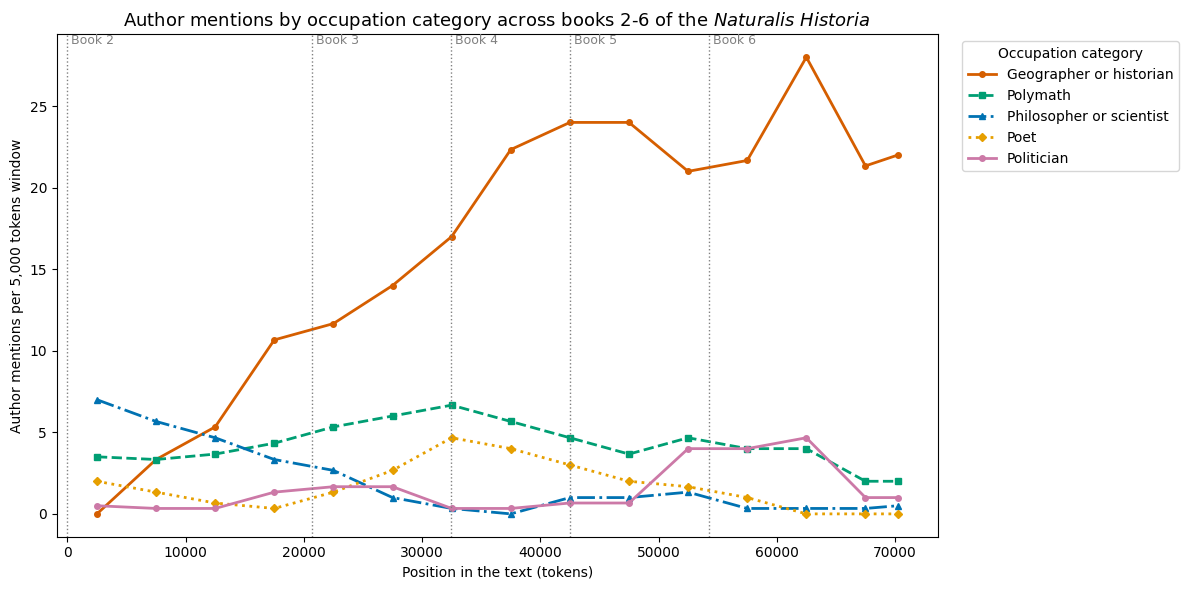

In [173]:
# color and style maps

styles  = ['-', '--', '-.', ':']
markers = ['o', 's', '^', 'D']

color_map = {
    'philoscientist':  '#0072B2',
    'geohistorian': '#D55E00',
    'polymath': '#009E73',
    'poet': '#E69F00',
    'politician':   '#CC79A7',
}


#define order
order = ['geohistorian', 'polymath', 'philoscientist', 'poet' , 'politician']
#make better names
new_names = {
    'geohistorian':   'Geographer or historian',
    'polymath':       'Polymath',
    'philoscientist': 'Philosopher or scientist',
    'poet':           'Poet',
    'politician':     'Politician',
}

# Denominator: all tokens in each window (PERS or not)
tokens_per_window = nh.groupby('window').size()  
#counts of authiors
counts = pd.crosstab(nh_authors['window'], nh_authors['occupation_category'])
counts = counts.reindex(index=tokens_per_window.index, columns=order, fill_value=0)

#Smooth to make trends easier to see
smooth = counts.rolling(window=3, center=True, min_periods=1).mean()
# X axis: token position at the center of each window
x = tokens_per_window.index * window_size + tokens_per_window / 2

# --- Plot ---
fig, ax = plt.subplots(figsize=(12, 6))
for i, group in enumerate(smooth.columns):
    ax.plot(
        x, smooth[group],
        linestyle=styles[i % len(styles)],
        marker=markers[i % len(markers)], markersize=4,
        linewidth=2, label=new_names[group],
        color=color_map[group]
    )

# Mark where each book begins
book_starts = nh.reset_index().groupby('book', sort=False)['index'].min()
for book, start in book_starts.items():
    ax.axvline(start, color='gray', linestyle=':', linewidth=1)
    ax.text(start, ax.get_ylim()[1], f' Book {book}', va='top', fontsize=9, color='gray')

ax.set_xlabel('Position in the text (tokens)')
ax.set_ylabel(f'Author mentions per {window_size:,} tokens window')
ax.set_title(r'Author mentions by occupation category across books 2-6 of the $\mathit{Naturalis\ Historia}$ ', fontsize=13)
ax.legend(title='Occupation category', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

#---save graph ---
# plt.savefig('occ_authors_across_books.pdf')

### Politicians vs Non-Politician

In [175]:
#set all to string to make the comparison, if pandas reads it incorrectly
mapping = {
    True: 'True', False: 'False',
    'True': 'True', 'False': 'False',
    'unspec': 'True', #set Nechepsos and Petosiris to True
}
nh_authors['is_politician'] = nh_authors['is_politician'].map(mapping)

print(nh_authors['is_politician'].value_counts(dropna=False))

is_politician
False    226
True     153
Name: count, dtype: int64


C:\Users\u0172188\AppData\Local\Temp\ipykernel_72268\2041481085.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  nh_authors['is_politician'] = nh_authors['is_politician'].map(mapping)


We calculate how often each author with political status is mentioned

In [177]:
unique_authors_total = nh_authors.drop_duplicates(subset='wikidata_qid')

per_author = nh_authors.groupby(['is_politician', 'wikidata_qid']).size()

comparison = pd.DataFrame({
    'mean': per_author.groupby('is_politician').mean(),
    'median': per_author.groupby('is_politician').median(),
    'total': nh_authors['is_politician'].value_counts(),
    'unique': unique_authors_total['is_politician'].value_counts(),
})

print(comparison)

                   mean  median  total  unique
is_politician                                 
False          2.897436     1.0    226      78
True           5.100000     2.5    153      30


#### Statistical test

In [179]:
author_stats = nh_authors.groupby(['wikidata_qid', 'Wikidata_label', 'occupation_category', 'is_politician', 
                                'language_group']).size().reset_index(name='n_mentions')

In [181]:

pol = author_stats[author_stats['is_politician']=='True']['n_mentions']
non_pol = author_stats[author_stats['is_politician']=='False']['n_mentions']


stat, p = mannwhitneyu(pol, non_pol, alternative='Greater') #adjust to two-sided if needed
print(f"Mann-Whitney U = {stat:.3f}, p-value = {p:.4f}")

Mann-Whitney U = 1486.500, p-value = 0.0111


## Chronology

We plot a bar chart showing how different chronological periods are distributed in each book.

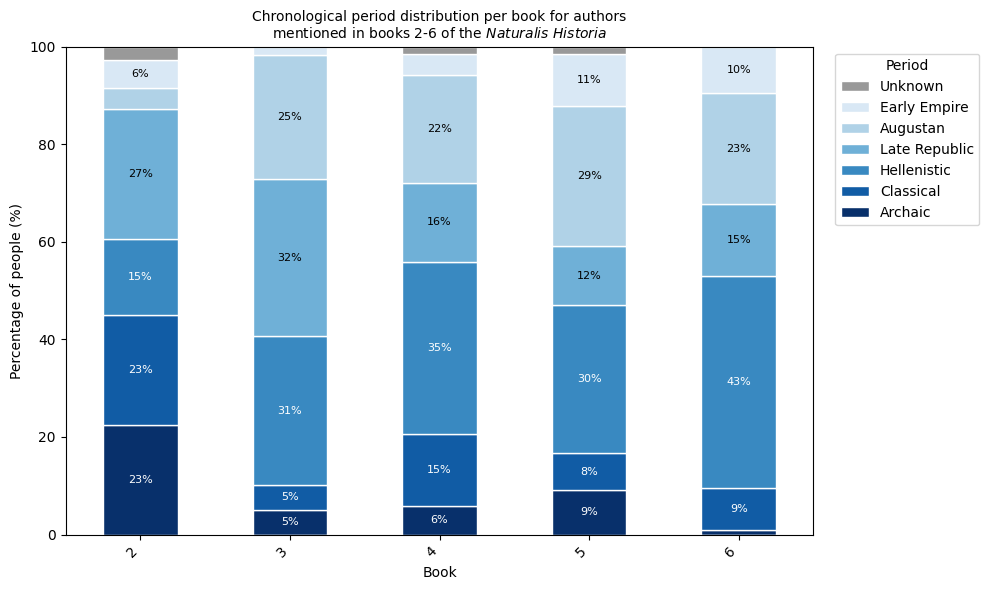

In [183]:
periods = ['archaic', 'classic', 'hellenistic', 'late_republic', 'augustean', 'early_empire']

#define the shades
shades = plt.cm.Blues(np.linspace(1, 0.15, len(periods)))   # dark -> light
color_map = dict(zip(periods, shades))
color_map['unknown'] = '#999999'

#make better looking names
new_names = {
    'archaic':   'Archaic',
    'classic':       'Classical',
    'hellenistic': 'Hellenistic',
    'late_republic':           'Late Republic',
    'augustean':     'Augustan',
    'early_empire': 'Early Empire',
    'unknown' : 'Unknown'
}
#group by chronological periods
chron_grouped = nh_authors.groupby(['book', 'period_final']).size()

# Pivot: rows = books, columns = citizenship groups
counts = chron_grouped.unstack(fill_value=0)

# Convert to percentages per book (each row sums to 100)
percentages = counts.div(counts.sum(axis=1), axis=0) * 100

#set the periods in the defined order
order = periods + ['unknown']
percentages = percentages.reindex(columns=[p for p in order if p in percentages.columns])

#plot
ax = percentages.plot(
    kind='bar', stacked=True, figsize=(10, 6),
    color=[color_map[p] for p in percentages.columns],
    edgecolor='white'
)
#define text color
text_colors = ['white', 'white', 'white', 'black', 'black', 'black', 'white']

#setting labels on the bars
for container, tc in zip(ax.containers, text_colors):
    labels = [f'{v:.0f}%' if v >= 5 else '' for v in container.datavalues]
    ax.bar_label(container, labels=labels, label_type='center', fontsize=8, color=tc)

ax.set_ylabel('Percentage of people (%)')
ax.set_xlabel('Book')
title = r'Chronological period distribution per book for authors mentioned in books 2-6 of the $\mathit{Naturalis\ Historia}$'
ax.set_title('\n'.join(textwrap.wrap(title, width=60)), fontsize=10)
ax.set_ylim(0, 100)
plt.xticks(rotation=45, ha='right')
plt.legend(title='Period', bbox_to_anchor=(1.02, 1), loc='upper left')

#setting legend
handles, labels = ax.get_legend_handles_labels()
labels = [new_names[l] for l in labels]
ax.legend(handles[::-1], labels[::-1], title='Period',
          bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()


plt.show()

#---save file---
# plt.savefig('chronology_authors.pdf')

### Augustan vs Not-Augustan

We calculate how often each Augustan author is mentioned.

In [185]:
author_stats = nh_authors.groupby(['wikidata', 'Wikidata_label', 
                                'period_final']).size().reset_index(name='n_mentions')

author_stats['is_augustan'] = author_stats['period_final'].eq('augustean').map(
    {True: 'augustan', False: 'non_augustan'}
)

summary = author_stats.groupby('is_augustan').agg(
    mean=('n_mentions', 'mean'),
    median=('n_mentions', 'median'),
    tot_mentions=('n_mentions', 'sum'),
    nr_authors=('wikidata', 'nunique')
)

summary

,mean,median,tot_mentions,nr_authors
is_augustan,,,,
augustan,13.00000,10.5,78,6
non_augustan,2.95098,2.0,301,102


#### Statistical test

In [187]:
august = author_stats[author_stats['period_final']=='augustean']['n_mentions']
non_august = author_stats[author_stats['period_final'] != 'augustean']['n_mentions']


stat, p = mannwhitneyu(august, non_august, alternative='Greater') #adjust to two-sided
print(f"Mann-Whitney U = {stat:.3f}, p-value = {p:.4f}")

Mann-Whitney U = 469.500, p-value = 0.0105
